# Capstone Project — Clustering Track
## 23CSE301 Machine Learning · B.Tech. CSE (III Year) · Academic Year 2026-27 · Review 2

**Dataset:** Dry Bean Dataset (Koklu & Ozkan, 2020) — 13,611 dry beans, 16 geometric/shape features extracted from images, 7 registered varieties.
**Track:** Clustering — K-Means and Agglomerative Hierarchical Clustering.
**Team:** *<Member 1 – CB.SC.U4CSE24712>, <Member 2 – CB.SC.U4CSE24761>, <Member 3 – CB.SC.U4CSE24727>*

---

### Problem statement
Dry beans are graded into seven varieties (Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira). Grading normally needs a human expert or a labelled image classifier. Here we ask a purely **unsupervised** question:

> *Using only the 16 geometric features extracted from bean images — with no access to the variety labels during training — can K-Means and Agglomerative Hierarchical Clustering discover groups that correspond to meaningful bean varieties, and which algorithm / configuration recovers this structure best?*

The `Class` column is **never** used while fitting or tuning a model. It is used only *afterwards*, to interpret and validate the discovered clusters, exactly as the course guidelines require.

### Guideline coverage map

| Guideline requirement | Where in this notebook |
|---|---|
| Dataset loading, audit (A1) | Section 2 |
| EDA — distributions, outliers, correlation, scatter plots + written insight commentary (A2, A3) | Section 3 |
| Cleaning, scaling (justified), feature-space variants (B1, B2) | Section 4 |
| K-Means implementation + mandatory **Elbow curve** (inertia vs k) | Section 6 |
| Agglomerative implementation + mandatory **Dendrogram**, linkage comparison | Section 7 |
| **Hyperparameter tuning** for both algorithms | Section 8 |
| Silhouette, Davies-Bouldin, Calinski-Harabasz reported for **every** algorithm/variant | Sections 5, 9 |
| **PCA (2 components) plot for every algorithm** (mandatory) + **t-SNE** (encouraged) | Section 10 |
| Cluster interpretation, profiling, post-hoc validation against true varieties | Section 11 |
| Robustness / generalisation checks (train-only scaler fit, seed stability) | Section 12 |
| Final model selection, conclusions | Section 13 |
| Saved artefacts for a bonus GUI (`models/kmeans_final_pipeline.pkl`) | Section 14 |

### How to run
1. Place `Dry_Bean_Dataset.xlsx` in `data/` (repo layout: `notebooks/`, `data/`, `models/`).
2. `pip install -r requirements.txt` (numpy, pandas, scipy, scikit-learn, matplotlib, seaborn, joblib, openpyxl).
3. **Kernel → Restart & Run All** (about 5-10 minutes on a laptop; the K-Means tuning grid and t-SNE dominate the run time).

## 1. Setup
`random_state = 42` is used everywhere so results are reproducible (guideline §7.1). The Seaborn **colorblind** palette is used throughout (guideline §7.3).

In [1]:
import os, time, itertools, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure,
                             pairwise_distances_argmin)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
PAL = sns.color_palette("colorblind", 10)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 8})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# Expected repo layout: notebooks/ (this file), data/, models/. Falls back gracefully if run elsewhere.
DATA_CANDIDATES = ["../data/Dry_Bean_Dataset.xlsx", "data/Dry_Bean_Dataset.xlsx",
                   "Dry_Bean_Dataset.xlsx", "/mnt/user-data/uploads/Dry_Bean_Dataset.xlsx"]
DATA_PATH = next(p for p in DATA_CANDIDATES if os.path.exists(p))
MODELS_DIR = Path("../models") if Path("../data").exists() else Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Data file :", DATA_PATH)
print("Models dir:", MODELS_DIR)

Data file : Dry_Bean_Dataset.xlsx
Models dir: models


## 2. Dataset Loading & Audit
We report shape, dtypes, missing values, duplicates, and the (held-out) class distribution, per guideline **A1**. Two column names are tidied (`AspectRation → AspectRatio`, `roundness → Roundness`) — purely cosmetic.

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name="Dry_Beans_Dataset")
raw = raw.rename(columns={"AspectRation": "AspectRatio", "roundness": "Roundness"})

print(f"Shape                : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Total missing values : {int(raw.isna().sum().sum())}")
print(f"Duplicate rows       : {int(raw.duplicated().sum())}")
print("\nData types:")
display(raw.dtypes.rename("dtype").to_frame().T)
print("\nFirst five rows:")
display(raw.head())
print("\nDescriptive statistics:")
display(raw.describe().T.round(3))

Shape                : 13,611 rows x 17 columns
Total missing values : 0
Duplicate rows       : 68

Data types:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
dtype,int64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str



First five rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


,count,share_%
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


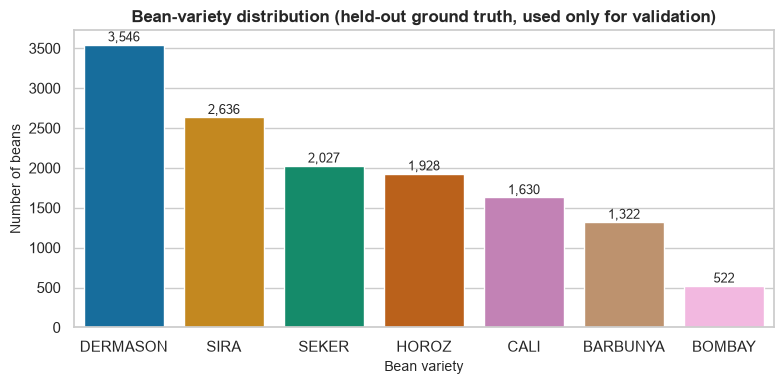

In [3]:
class_counts = raw["Class"].value_counts()
class_share = (class_counts / len(raw) * 100).round(2)
display(pd.DataFrame({"count": class_counts, "share_%": class_share}))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette="colorblind", legend=False, ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 40, f"{v:,}", ha="center", fontsize=9)
ax.set_title("Bean-variety distribution (held-out ground truth, used only for validation)")
ax.set_xlabel("Bean variety"); ax.set_ylabel("Number of beans")
plt.tight_layout(); plt.show()

**Observation.** The dataset has 13,611 beans, 16 numeric shape features, and no missing values, so no imputation is required. 68 exact duplicate rows are present (all belonging to the Horoz variety); they are removed in Section 4. The seven varieties are **imbalanced**: Dermason (~26%) and Sira (~19%) dominate, while Bombay is by far the rarest at only 522 beans (~3.8% of the data). This matters for clustering because a naive algorithm can easily merge Bombay into a neighbouring cluster or, conversely, an algorithm that isolates a handful of extreme points can masquerade as "finding" Bombay — both failure modes are guarded against by the cluster-size validity filter defined in Section 5.

## 3. Exploratory Data Analysis (EDA)
### 3.1 Feature distributions

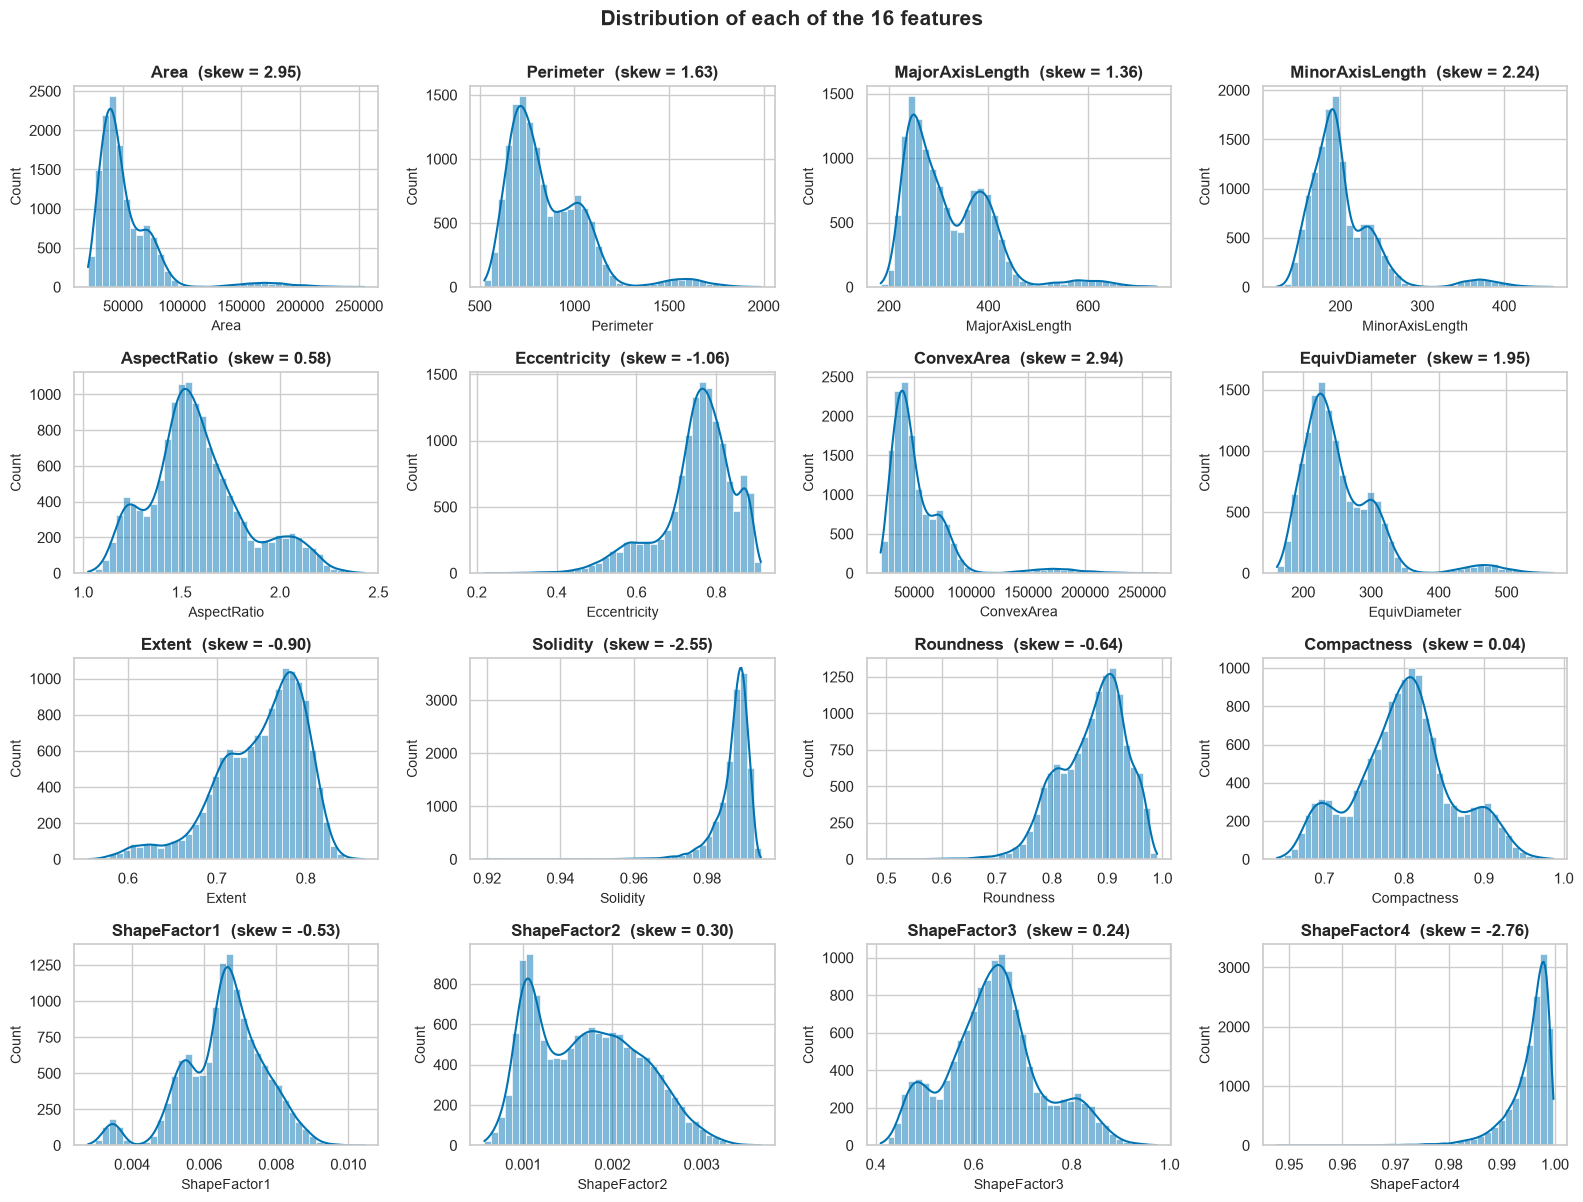

Most right-skewed features : {'Area': 2.95, 'ConvexArea': 2.94, 'MinorAxisLength': 2.24, 'EquivDiameter': 1.95}
Most left-skewed features  : {'Extent': -0.9, 'Eccentricity': -1.06, 'Solidity': -2.55, 'ShapeFactor4': -2.76}


In [4]:
feature_cols = [c for c in raw.columns if c != "Class"]
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.histplot(raw[col], kde=True, bins=40, color=PAL[0], ax=ax)
    ax.set_title(f"{col}  (skew = {raw[col].skew():.2f})")
    ax.set_xlabel(col); ax.set_ylabel("Count")
fig.suptitle("Distribution of each of the 16 features", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

skew_tbl = raw[feature_cols].skew().sort_values(ascending=False).round(2)
print("Most right-skewed features :", skew_tbl.head(4).to_dict())
print("Most left-skewed features  :", skew_tbl.tail(4).to_dict())

**Observation.** The size-related features (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`, `MajorAxisLength`) are right-skewed with a long upper tail — this tail is largely the large-bodied Bombay variety sitting apart from the other six. Shape-descriptor features that are ratios (`Eccentricity`, `Solidity`, `Extent`, `Roundness`, `Compactness`, `ShapeFactor1-4`) are on very different scales from the size features and several (e.g. `Solidity`, `Extent`) are strongly left-skewed with tight concentration near 1, which limits how much separating power they contribute on their own. The wildly different scales (`Area` in the tens of thousands versus `Solidity` near 1) also make scaling non-optional for distance-based clustering.

### 3.2 Outlier view (IQR rule) and box-plots

feature,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
n_outliers,551.00,500.00,379.00,569.00,473.00,843.00,550.00,526.00,275.00,778.00,91.00,109.0,533.00,0.0,195.00,767.00
outlier_%,4.05,3.67,2.78,4.18,3.48,6.19,4.04,3.86,2.02,5.72,0.67,0.8,3.92,0.0,1.43,5.64


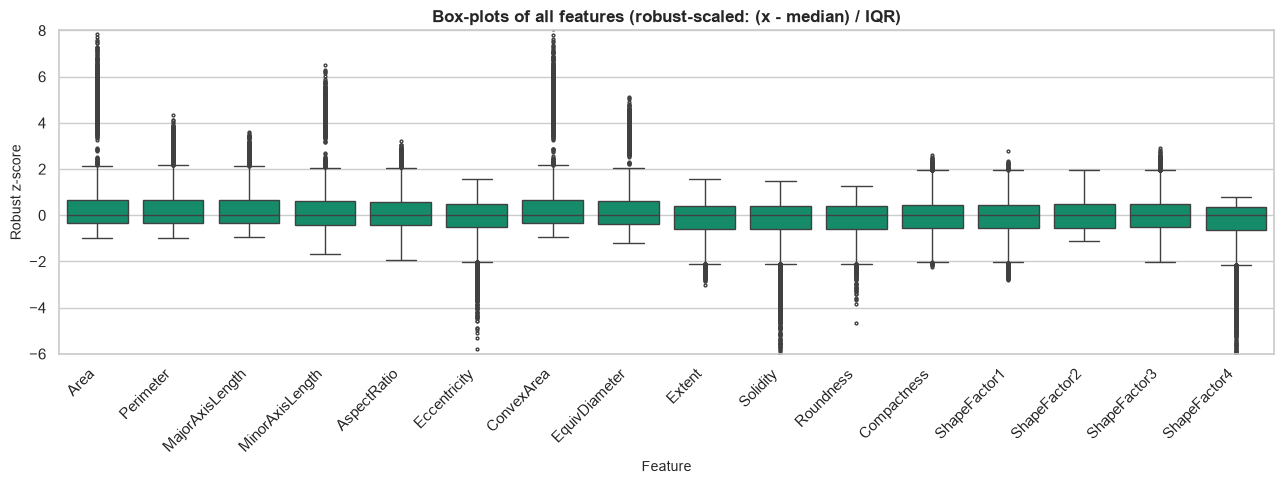

In [5]:
def iqr_outlier_table(df, cols):
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
        rows.append((c, n_out, round(100 * n_out / len(df), 2)))
    return pd.DataFrame(rows, columns=["feature", "n_outliers", "outlier_%"]).set_index("feature")

out_tbl = iqr_outlier_table(raw, feature_cols)
display(out_tbl.T)

Zbox = (raw[feature_cols] - raw[feature_cols].median()) / (raw[feature_cols].quantile(.75) - raw[feature_cols].quantile(.25))
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=Zbox, orient="v", color=PAL[2], fliersize=2, ax=ax)
ax.set_title("Box-plots of all features (robust-scaled: (x - median) / IQR)")
ax.set_xlabel("Feature"); ax.set_ylabel("Robust z-score"); ax.set_ylim(-6, 8)
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**Observation.** IQR-flagged outliers appear in essentially every feature, and are most numerous in the size-related features and in some shape ratios (e.g. `Solidity`, `Extent`, `Compactness`). Inspecting them shows they are real, physically plausible beans (the large-bodied Bombay beans, and beans with irregular outlines or imperfect image segmentation), not sensor or data-entry errors. We therefore retain all rows and manage their influence on distance-based clustering through the choice of **scaler** (Standard vs Robust vs Min-Max) that is tuned in Section 8, rather than deleting data — deleting them would remove exactly the Bombay cluster we hope to discover.

### 3.3 Correlation heat-map

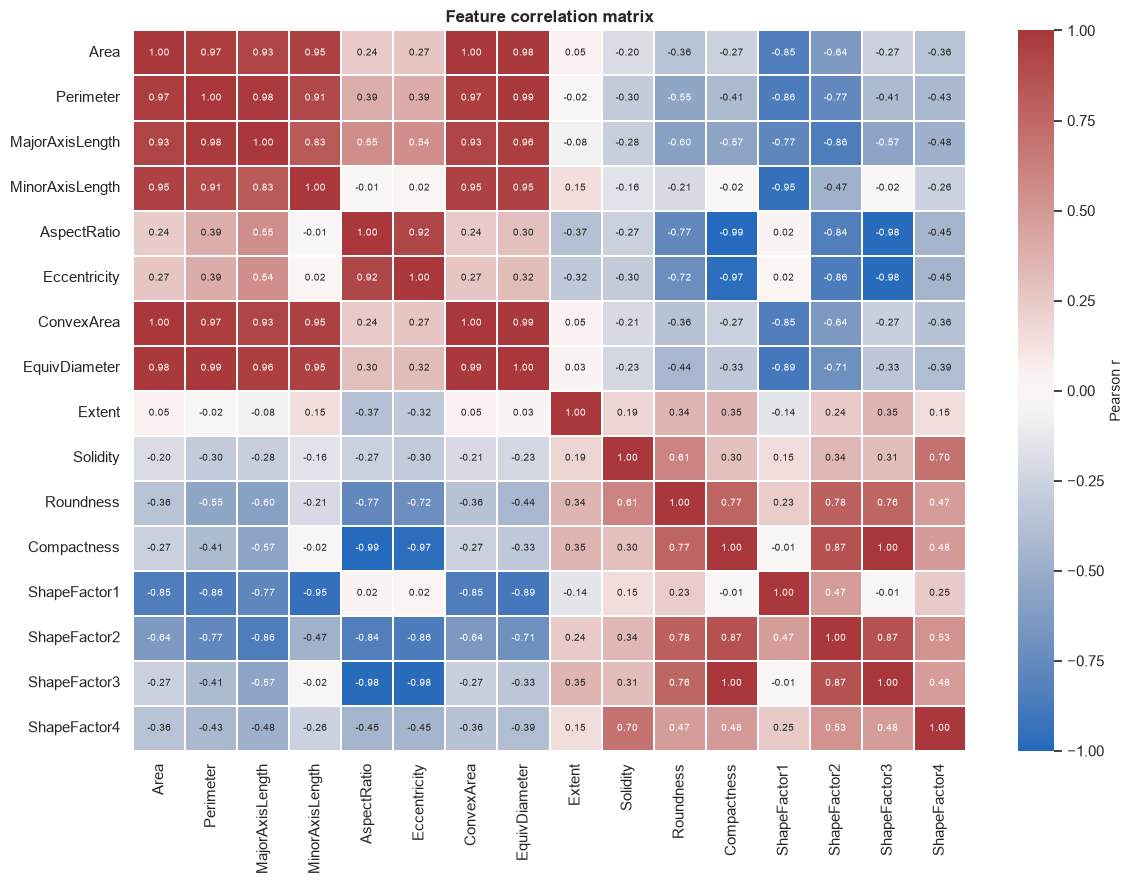

Most correlated feature pairs:


,,|r|
Area,ConvexArea,0.9999
Compactness,ShapeFactor3,0.9987
Perimeter,EquivDiameter,0.9914
AspectRatio,Compactness,0.9877
ConvexArea,EquivDiameter,0.9852
Area,EquivDiameter,0.9850
Eccentricity,ShapeFactor3,0.9811
AspectRatio,ShapeFactor3,0.9786


In [6]:
corr = raw[feature_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=.3, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Feature correlation matrix")
plt.tight_layout(); plt.show()

upper = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool))
top_pairs = upper.stack().sort_values(ascending=False).head(8).round(4)
print("Most correlated feature pairs:"); display(top_pairs.rename("|r|").to_frame())

**Observation.** `Area`, `Perimeter`, `ConvexArea`, `EquivDiameter` and `MajorAxisLength` are almost perfectly correlated (|r| close to 1) — unsurprising, since they are five different mathematical ways of measuring the same underlying "how big is this bean" quantity. `Compactness`, `ShapeFactor1`, `AspectRatio`, `Eccentricity` and `ShapeFactor3` also correlate strongly with each other, as they all encode elongation/circularity. This redundancy means K-Means (which uses Euclidean distance) would otherwise let "size" and "elongation" dominate the distance calculation several times over; the `decorr` feature-space variant built in Section 4.3 corrects for this.

### 3.4 Feature–feature scatter plots and pair-plot
Colours below show the true variety **for interpretation only** — no clustering algorithm sees this column.

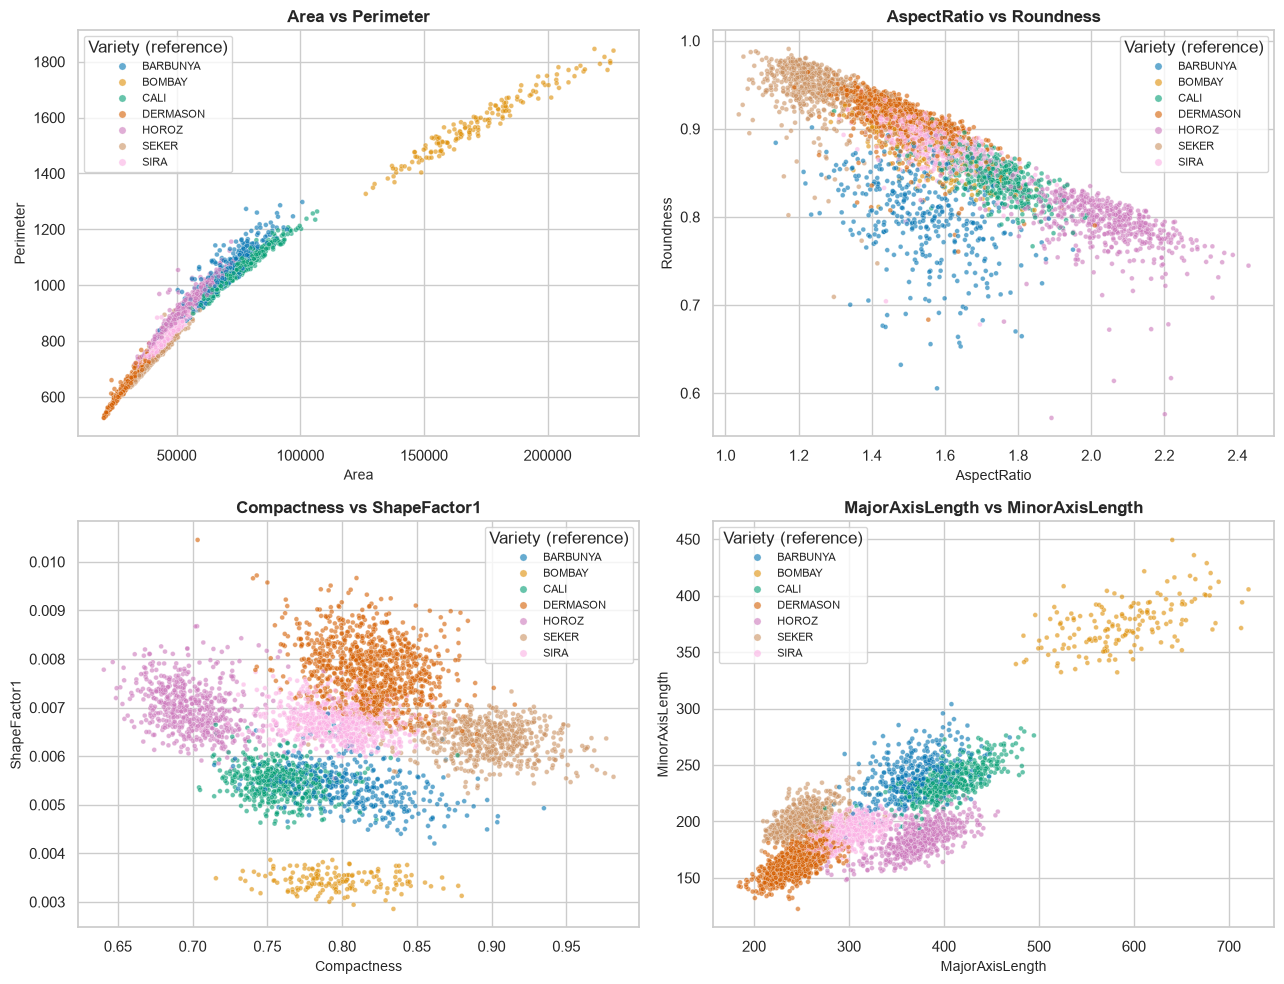

In [7]:
pairs = [("Area", "Perimeter"), ("AspectRatio", "Roundness"), ("Compactness", "ShapeFactor1"), ("MajorAxisLength", "MinorAxisLength")]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
order = sorted(raw["Class"].unique())
for ax, (a, b) in zip(axes.ravel(), pairs):
    sns.scatterplot(data=raw.sample(4000, random_state=RANDOM_STATE), x=a, y=b, hue="Class", hue_order=order,
                    palette="colorblind", s=12, alpha=.6, ax=ax)
    ax.set_title(f"{a} vs {b}"); ax.legend(title="Variety (reference)", loc="best", markerscale=1.5)
plt.tight_layout(); plt.show()

**Observation.** `Area` vs `Perimeter` shows Bombay clearly separated in the upper-right corner, with the remaining six varieties forming a dense, overlapping band — consistent with Bombay being trivial to isolate but the other varieties requiring finer shape cues. `AspectRatio` vs `Roundness` shows the expected inverse relationship: elongated varieties (Horoz, Sira) sit at high aspect ratio / low roundness, while round varieties (Seker, Bombay) sit at the opposite end. This is encouraging: the *shape* features, not just size, carry real discriminating signal for clustering.

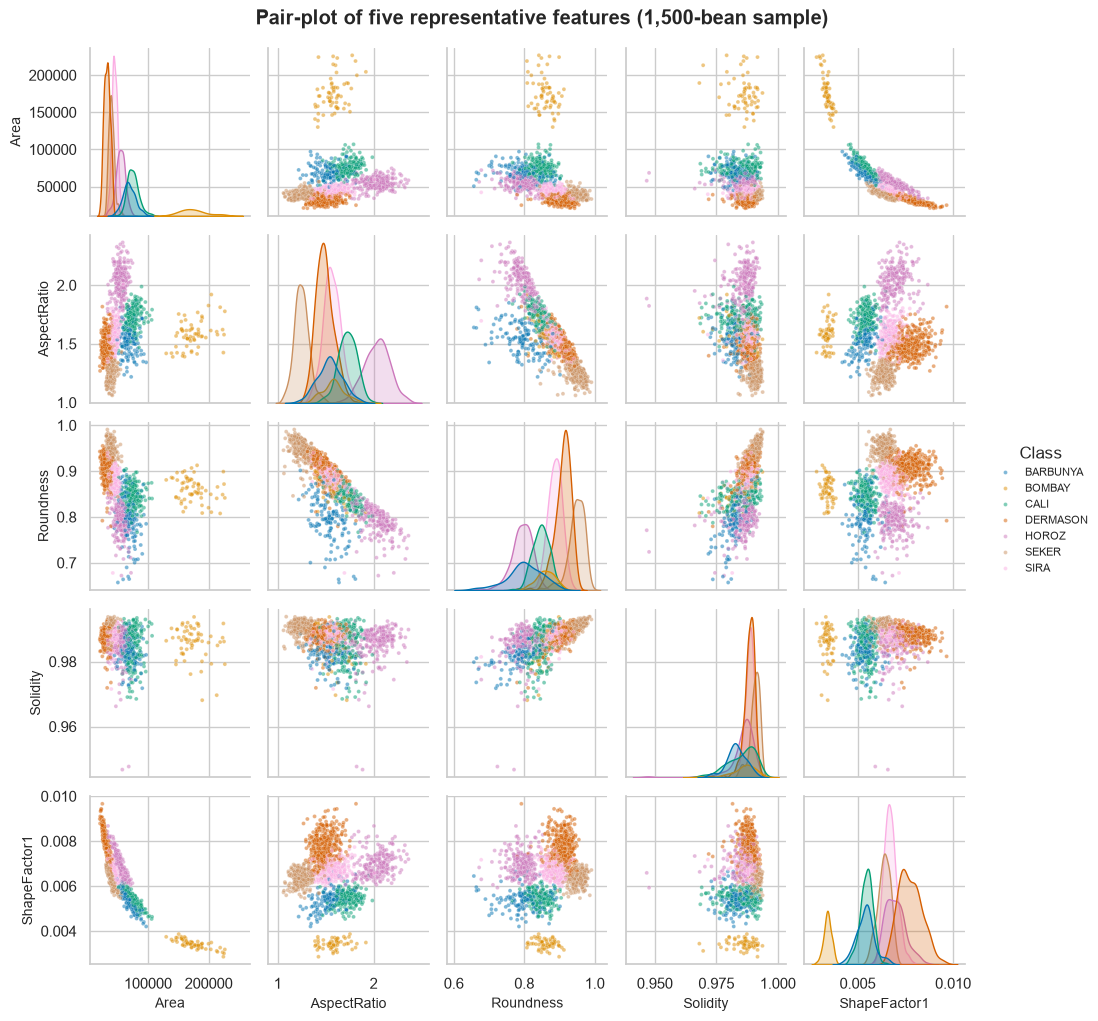

In [8]:
sel = ["Area", "AspectRatio", "Roundness", "Solidity", "ShapeFactor1"]
g = sns.pairplot(raw.sample(1500, random_state=RANDOM_STATE), vars=sel, hue="Class", hue_order=order,
                 palette="colorblind", plot_kws={"s": 8, "alpha": .5}, diag_kind="kde", height=2.0)
g.figure.suptitle("Pair-plot of five representative features (1,500-bean sample)", y=1.02, fontweight="bold")
plt.show()

**Observation.** The diagonal KDEs confirm Bombay is unimodal and well-separated on `Area`, while the other six varieties overlap heavily in most 2-D projections and are only partially separable pairwise — meaning a clustering algorithm will likely need the *full* multi-dimensional feature space (or a PCA summary of it) rather than any single 2-feature pair to recover all seven groups.

## 4. Preprocessing & Feature-Space Design
### 4.1 Cleaning — duplicates, missing values, outliers
**Strategy and justification** (guideline **B1**)

* **Duplicates** — exact duplicate rows add no information and would give some points double weight in a distance-based algorithm, so they are dropped.
* **Missing values** — none are present (confirmed in Section 2). The code still contains a defensive median-imputation step so the pipeline is safe if the source file is refreshed.
* **Outliers** — flagged with the IQR rule in Section 3.2 but **retained**: they are real, physically plausible beans (e.g. the large-bodied *Bombay* variety), not measurement errors. Their effect on K-Means is managed instead by comparing scalers during tuning.
* **Labels** — separated into `y_true` and used **only** for post-hoc validation, never for fitting or tuning.

In [9]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Removed {len(raw) - len(df)} duplicate rows -> {len(df):,} rows remain")

if df[feature_cols].isna().any().any():                      # defensive; not triggered for this dataset
    df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())
assert df[feature_cols].isna().sum().sum() == 0

X = df[feature_cols].copy()          # unlabeled feature matrix: the ONLY thing models see
y_true = df["Class"].copy()          # held-out labels: used only for post-hoc validation
N = len(X)
print("X shape:", X.shape, "| y_true classes:", y_true.nunique())

Removed 68 duplicate rows -> 13,543 rows remain
X shape: (13543, 16) | y_true classes: 7


### 4.2 Scaling and the reference feature space

Features live on very different scales (`Area` ~ 10⁴–10⁵, `Solidity` ~ 1), and both clustering algorithms use distance-based calculations, so scaling is required.

For the primary unsupervised analysis, the complete unlabeled feature dataset is standardized to create a common reference space. This allows the clustering structure of the available dataset to be examined without introducing a supervised target into model fitting.

The `Class` column is never used to fit or tune the clustering algorithms.

To additionally verify that the preprocessing and selected K-Means configuration remain valid when applied to unseen observations, Section 12.2 performs a separate leakage-safe 80/20 hold-out experiment. In that experiment, the scaler is fitted only on the training data and the held-out test data is transformed using that fitted scaler.

Therefore:

- **Primary clustering analysis:** complete unlabeled dataset.
- **Robustness/generalisation check:** train-only scaler fitting followed by evaluation on an untouched 20% test split.
- **Post-hoc validation:** `Class` is used only after clustering through ARI, NMI, purity and related measures.

All primary clustering-quality metrics are computed in one common reference space so that candidate configurations can be compared consistently.

In [10]:
REF = StandardScaler().fit_transform(X)          # reference space used for ALL metric comparisons
REF_DF = pd.DataFrame(REF, columns=feature_cols)
print("Reference matrix:", REF.shape, "| mean ~", REF.mean().round(6), "| std ~", REF.std().round(3))

def hopkins(Z, m=600, seed=RANDOM_STATE):
    # Hopkins statistic: ~0.5 = uniformly random data, -> 1.0 = strongly clustered
    rng = np.random.RandomState(seed); n, d = Z.shape
    nn = NearestNeighbors(n_neighbors=2).fit(Z)
    real = Z[rng.choice(n, m, replace=False)]
    w = nn.kneighbors(real, n_neighbors=2)[0][:, 1]                      # real point -> nearest OTHER real point
    U = rng.uniform(Z.min(0), Z.max(0), (m, d))
    u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]                         # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

H = np.mean([hopkins(REF, seed=s) for s in range(5)])
print(f"Hopkins statistic (mean of 5 runs): {H:.3f}  ->  " +
      ("strong cluster tendency" if H > 0.75 else "moderate cluster tendency" if H > 0.6 else "weak / no cluster tendency"))

Reference matrix: (13543, 16) | mean ~ 0.0 | std ~ 1.0
Hopkins statistic (mean of 5 runs): 0.953  ->  strong cluster tendency


**Observation.** A Hopkins statistic well above 0.5 (printed above; 0.5 = uniform random data, 1.0 = perfectly clustered) indicates genuine cluster tendency in the data rather than a uniform blob — i.e. clustering this dataset is a meaningful exercise and not something being forced onto random noise.

### 4.3 Feature-space variants (feature selection / extraction)
Several features are near-duplicates of each other (Section 3.3). We prepare three feature spaces and let the tuning stage in Section 8 decide which works best:

| Variant | Description |
|---|---|
| `all` | all 16 original features |
| `decorr` | drop one feature from every pair with \|r\| > 0.95 (removes redundancy so "size" is not effectively counted five times) |
| `pca95` | standardise, then PCA keeping 95% of the variance |

Dropped as redundant (|r| > 0.95): ['Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter', 'Compactness', 'ShapeFactor3']
Decorrelated set (9 features): ['Area', 'AspectRatio', 'Eccentricity', 'Extent', 'Solidity', 'Roundness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor4']

PCA: 4 components explain 95.0% of variance; first 2 explain 81.9%


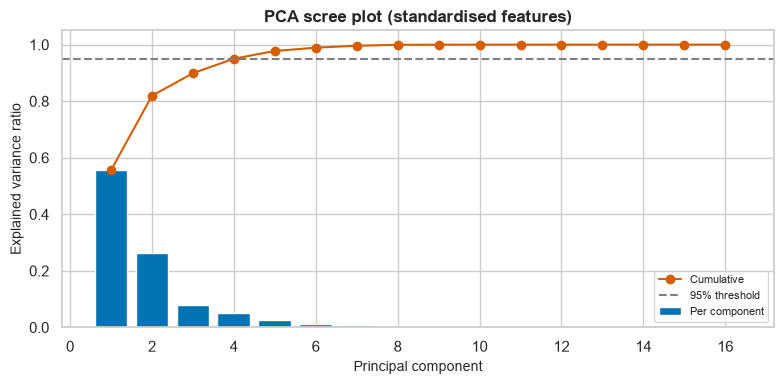

In [11]:
corr_abs = X.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), 1).astype(bool))
DROP_REDUNDANT = [c for c in upper.columns if (upper[c] > 0.95).any()]
DECORR_COLS = [c for c in feature_cols if c not in DROP_REDUNDANT]
print("Dropped as redundant (|r| > 0.95):", DROP_REDUNDANT)
print(f"Decorrelated set ({len(DECORR_COLS)} features):", DECORR_COLS)

pca_full = PCA(random_state=RANDOM_STATE).fit(REF)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"\nPCA: {n95} components explain {cum[n95-1]*100:.1f}% of variance; first 2 explain {cum[1]*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 17), pca_full.explained_variance_ratio_, color=PAL[0], label="Per component")
ax.plot(range(1, 17), cum, "o-", color=PAL[3], label="Cumulative")
ax.axhline(.95, ls="--", color="gray", label="95% threshold")
ax.set_title("PCA scree plot (standardised features)"); ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio")
ax.legend(); plt.tight_layout(); plt.show()

**Observation.** Because several features are near-duplicate measures of size and elongation, the first two principal components already absorb a large share of the total variance and only a handful of components are needed to reach the 95% threshold (exact numbers printed above). This confirms the feature set is highly redundant and justifies testing the `decorr` and `pca95` variants alongside the full 16-feature space during tuning.

In [12]:
SCALERS = {"standard": StandardScaler, "robust": RobustScaler, "minmax": MinMaxScaler}
FSETS = ["all", "decorr", "pca95"]

def build_features(scaler_name, fset, data=X):
    # Returns the model-input matrix for a (scaler, feature-set) combination.
    cols = feature_cols if fset in ("all", "pca95") else DECORR_COLS
    Z = SCALERS[scaler_name]().fit_transform(data[cols])
    if fset == "pca95":
        Z = PCA(n_components=0.95, random_state=RANDOM_STATE).fit_transform(Z)
    return Z

FEATS = {(s, f): build_features(s, f) for s in SCALERS for f in FSETS}
print(pd.Series({f"{s}/{f}": v.shape[1] for (s, f), v in FEATS.items()}, name="n_features").to_frame().T)

            standard/all  standard/decorr  standard/pca95  robust/all  robust/decorr  robust/pca95  minmax/all  minmax/decorr  minmax/pca95
n_features            16                9               4          16              9             4          16              9             4


## 5. Evaluation Toolkit
**Internal metrics** (mandatory; require no labels; computed in the common reference space):

| Metric | Range | Better | Idea |
|---|---|---|---|
| Silhouette Score | -1 ... 1 | higher | how much closer a point is to its own cluster than to the nearest other cluster |
| Davies-Bouldin Index | 0 ... infinity | lower | average similarity between each cluster and its most similar one (scatter / separation) |
| Calinski-Harabasz Index | 0 ... infinity | higher | ratio of between-cluster to within-cluster dispersion |

**External metrics** (post-hoc only, using the held-out varieties): Adjusted Rand Index (ARI), Normalised Mutual Information (NMI), Homogeneity / Completeness / V-measure, and Purity.

**Validity filter.** Internal metrics can be "gamed" by degenerate solutions — e.g. single/average linkage often isolates 1-3 outlier beans in their own cluster, which inflates the silhouette artificially. During tuning, any configuration with a cluster holding **< 2% of the beans** is rejected. (The rarest real variety, *Bombay*, is ~3.8% of the data, so genuine solutions comfortably pass this filter.)

In [13]:
MIN_SHARE = 0.02      # validity filter used during tuning

def internal_metrics(Z, labels, sil_sample=None):
    return {"silhouette": silhouette_score(Z, labels, sample_size=sil_sample, random_state=RANDOM_STATE) if sil_sample else silhouette_score(Z, labels),
            "davies_bouldin": davies_bouldin_score(Z, labels),
            "calinski_harabasz": calinski_harabasz_score(Z, labels)}

def purity_score(y, labels):
    ct = pd.crosstab(labels, y)
    return ct.max(axis=1).sum() / ct.values.sum()

def external_metrics(y, labels):
    h, c, v = homogeneity_completeness_v_measure(y, labels)
    return {"ARI": adjusted_rand_score(y, labels), "NMI": normalized_mutual_info_score(y, labels),
            "homogeneity": h, "completeness": c, "v_measure": v, "purity": purity_score(y, labels)}

def min_cluster_share(labels):
    return np.bincount(labels).min() / len(labels)

def full_report(Z, labels, y=y_true, sil_sample=None):
    labels = np.asarray(labels)
    return {**internal_metrics(Z, labels, sil_sample), **external_metrics(y, labels),
            "n_clusters": len(np.unique(labels)), "min_share": min_cluster_share(labels)}

def composite_rank(grid, min_share=MIN_SHARE):
    # Rank valid configs on Silhouette (high), Davies-Bouldin (low), Calinski-Harabasz (high); lower mean rank = better.
    g = grid[grid["min_share"] >= min_share].copy()
    g["rank_sil"] = g["silhouette"].rank(ascending=False)
    g["rank_db"]  = g["davies_bouldin"].rank(ascending=True)
    g["rank_ch"]  = g["calinski_harabasz"].rank(ascending=False)
    g["mean_rank"] = g[["rank_sil", "rank_db", "rank_ch"]].mean(axis=1)
    return g.sort_values(["mean_rank", "silhouette"], ascending=[True, False]).reset_index(drop=True)

def relabel(lbl):
    # sklearn/scipy labels -> consecutive ints starting at 0
    return pd.factorize(np.asarray(lbl))[0]
print("Evaluation helpers ready.")

Evaluation helpers ready.


## 6. Algorithm 1 — K-Means Clustering
K-Means alternates between (a) assigning each bean to its nearest centroid and (b) moving each centroid to the mean of its beans, minimising **inertia** (within-cluster sum of squared distances). It needs `k` chosen in advance, so we use the mandatory **Elbow curve**, supported by the three internal metrics.

### 6.1 Elbow curve and metric-vs-k analysis

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
1,216688.0000,NaN,NaN,NaN
2,129194.0199,0.3943,1.0793,9170.3624
3,94331.7347,0.4028,0.9013,8781.2651
4,75993.1949,0.3428,0.9276,8355.4286
5,61624.6374,0.3596,1.0256,8516.2717
6,54900.7483,0.3611,0.9961,7978.4532
7,48671.4570,0.3102,1.1021,7787.8367
8,45083.3590,0.3026,1.1573,7359.9234
9,41904.8161,0.3007,1.1646,7056.2164


Elbow (knee) detected at k = 4


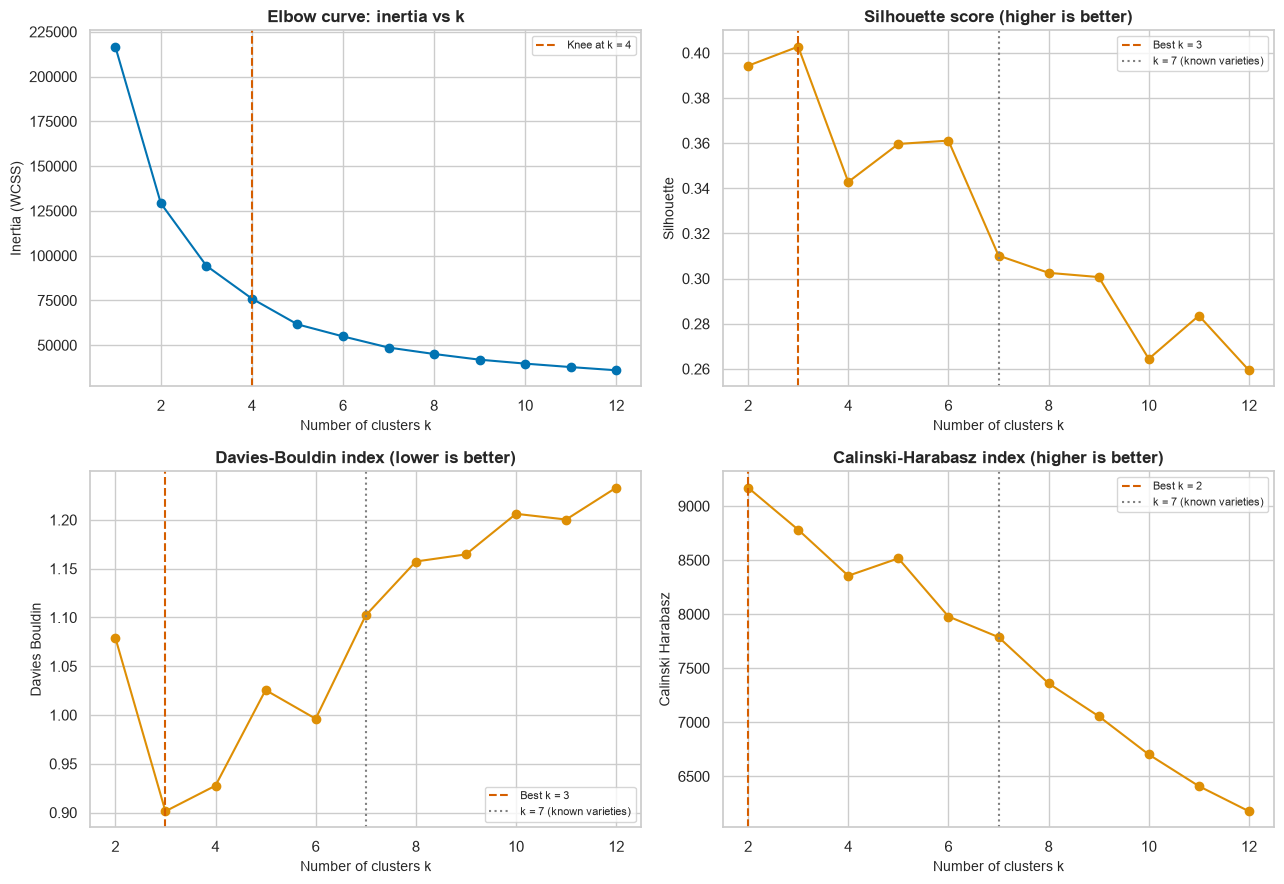

Knee of elbow curve: k = 4 | best silhouette: k = 3 | best Davies-Bouldin: k = 3 | best Calinski-Harabasz: k = 2


In [14]:
# K-Means k-selection using only label-free internal metrics.
# Ground-truth Class labels are intentionally NOT used here.

K_RANGE = list(range(1, 13))
rows = []

for k in K_RANGE:
    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE
    ).fit(REF)

    r = {
        "k": k,
        "inertia": km.inertia_
    }

    if k >= 2:
        r.update(
            internal_metrics(
                REF,
                km.labels_,
                sil_sample=5000
            )
        )

    rows.append(r)

elbow_df = pd.DataFrame(rows).set_index("k")

display(elbow_df.round(4))

# Automatic elbow/knee detection using the largest perpendicular
# distance from the chord joining the first and last points.
ks = np.array(K_RANGE, dtype=float)
inert = elbow_df["inertia"].values.astype(float)

kn = (ks - ks.min()) / (ks.max() - ks.min())
inn = (inert - inert.min()) / (inert.max() - inert.min())

p1 = np.array([kn[0], inn[0]])
p2 = np.array([kn[-1], inn[-1]])

dist_to_chord = [
    abs(
        (p2[0] - p1[0]) * (p1[1] - i)
        - (p1[0] - k) * (p2[1] - p1[1])
    ) / np.linalg.norm(p2 - p1)
    for k, i in zip(kn, inn)
]

K_KNEE = int(ks[int(np.argmax(dist_to_chord))])

print("Elbow (knee) detected at k =", K_KNEE)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Elbow curve
ax = axes[0, 0]
ax.plot(ks, inert, "o-", color=PAL[0])
ax.axvline(
    K_KNEE,
    ls="--",
    color=PAL[3],
    label=f"Knee at k = {K_KNEE}"
)
ax.set_title("Elbow curve: inertia vs k")
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Inertia (WCSS)")
ax.legend()

# Internal metrics
metric_specs = [
    (
        axes[0, 1],
        "silhouette",
        "Silhouette score (higher is better)",
        "max"
    ),
    (
        axes[1, 0],
        "davies_bouldin",
        "Davies-Bouldin index (lower is better)",
        "min"
    ),
    (
        axes[1, 1],
        "calinski_harabasz",
        "Calinski-Harabasz index (higher is better)",
        "max"
    )
]

for ax, col, title, better in metric_specs:
    s = elbow_df[col].dropna()

    ax.plot(
        s.index,
        s.values,
        "o-",
        color=PAL[1]
    )

    best_k = (
        s.idxmax()
        if better == "max"
        else s.idxmin()
    )

    ax.axvline(
        best_k,
        ls="--",
        color=PAL[3],
        label=f"Best k = {best_k}"
    )

    # k=7 is shown only as a domain reference.
    ax.axvline(
        7,
        ls=":",
        color="gray",
        label="k = 7 (known varieties)"
    )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters k")
    ax.set_ylabel(col.replace("_", " ").title())
    ax.legend()

plt.tight_layout()
plt.show()

k_sil = elbow_df["silhouette"].idxmax()
k_db = elbow_df["davies_bouldin"].idxmin()
k_ch = elbow_df["calinski_harabasz"].idxmax()

print(
    f"Knee of elbow curve: k = {K_KNEE} | "
    f"best silhouette: k = {k_sil} | "
    f"best Davies-Bouldin: k = {k_db} | "
    f"best Calinski-Harabasz: k = {k_ch}"
)

**Observation.** Note where the automatically detected "knee" (dashed line, top-left) falls relative to `k = 7` (dotted line, the known variety count). Internal metrics such as Silhouette and Davies-Bouldin often prefer a smaller `k` than 7, because several varieties (e.g. Dermason/Sira, or Cali/Horoz/Barbunya) are geometrically close and only weakly separable on shape alone — the elbow reflects the *coarse* structure of the data (roughly: "small round beans" vs "large beans" vs "elongated beans"), while `k = 7` reflects the *fine-grained* agronomic labelling. Both are legitimate reference points and are carried forward together into Section 8.

### 6.2 Per-sample silhouette diagrams
Wide, uniformly thick "knives" that extend beyond the average (red dashed line) indicate compact, well-separated clusters; thin knives or negative values indicate weak or overlapping clusters.

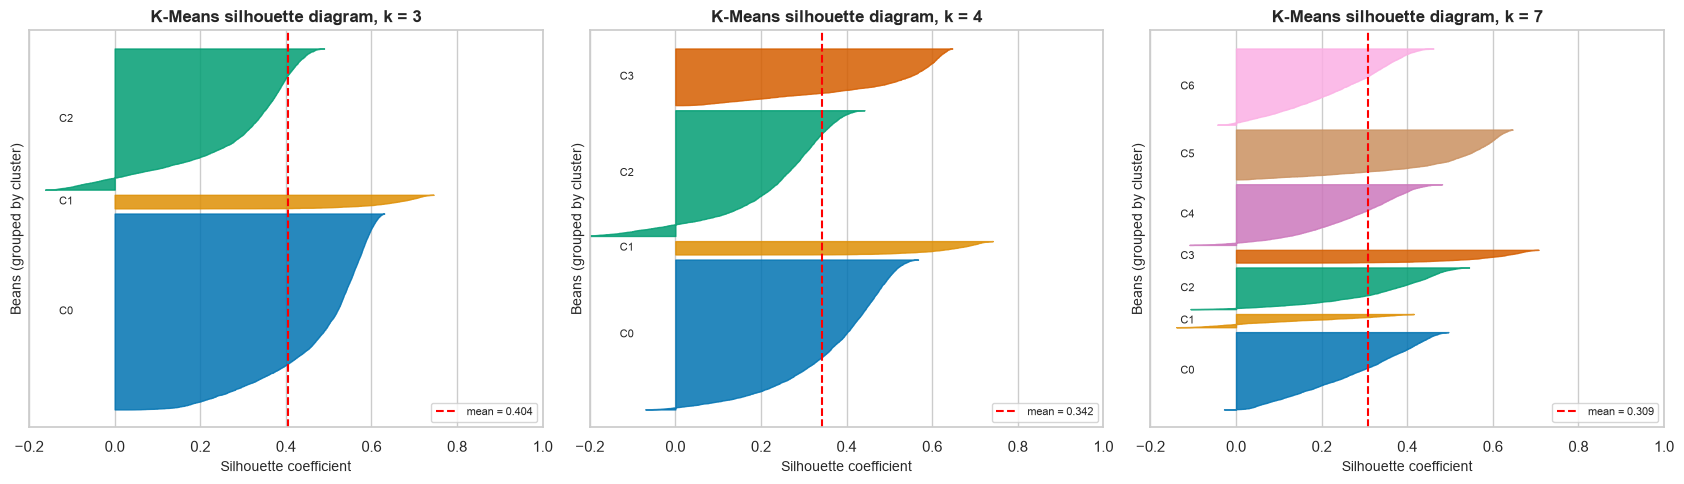

In [15]:
def silhouette_diagram(Z, labels, ax, title):
    s = silhouette_samples(Z, labels); k = len(np.unique(labels)); y0 = 200
    for c in range(k):
        v = np.sort(s[labels == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=PAL[c % 10], alpha=.85)
        ax.text(-0.13, y0 + len(v) / 2, f"C{c}", va="center", fontsize=8); y0 += len(v) + 200
    ax.axvline(s.mean(), color="red", ls="--", label=f"mean = {s.mean():.3f}")
    ax.set_title(title); ax.set_xlabel("Silhouette coefficient"); ax.set_ylabel("Beans (grouped by cluster)"); ax.set_yticks([]); ax.set_xlim(-0.2, 1); ax.legend(loc="lower right")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, k in zip(axes, [3, K_KNEE if K_KNEE not in (3, 7) else 5, 7]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(REF)
    silhouette_diagram(REF, lab, ax, f"K-Means silhouette diagram, k = {k}")
plt.tight_layout(); plt.show()

**Observation.** As `k` grows from 3 towards 7, one or two clusters typically remain wide and well above the mean line (the Bombay-dominated cluster and a large round-bean cluster), while others thin out and dip closer to zero (or below) — a sign that the finer 7-way split is statistically harder than the coarse 3-way split, consistent with the elbow-curve finding above.

### 6.3 Choosing the baseline `k`
Because the elbow curve has no razor-sharp bend and internal metrics can favour a coarser structure, we carry **two reference points** through the rest of the notebook:

* **k = 7** — domain prior: the dataset documents seven registered bean varieties, the natural granularity for a grading application.
* **k\*** (data-driven) — whichever `k` the internal metrics prefer during the Section 8 tuning grid.

The **baseline K-Means** below is scikit-learn's default configuration (k-means++ initialisation, default `n_init`) on standardised features with `k = 7`.

In [16]:
t0 = time.time()
km_base = KMeans(n_clusters=7, random_state=RANDOM_STATE).fit(REF)      # sklearn defaults otherwise
lab_km_base = km_base.labels_
print(f"Baseline K-Means fitted in {time.time()-t0:.2f}s | inertia = {km_base.inertia_:,.0f} | iterations = {km_base.n_iter_}")
print("Cluster sizes:", np.bincount(lab_km_base))
rep = full_report(REF, lab_km_base)
display(pd.Series(rep, name="K-Means baseline (k=7)").round(4).to_frame().T)

Baseline K-Means fitted in 0.01s | inertia = 51,639 | iterations = 18
Cluster sizes: [2682 3115 2036  925 3165  521 1099]


,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,homogeneity,completeness,v_measure,purity,n_clusters,min_share
K-Means baseline (k=7),0.2886,1.193,7210.5888,0.6496,0.71,0.7026,0.7175,0.71,0.807,7.0,0.0385


## 7. Algorithm 2 — Agglomerative Hierarchical Clustering
Agglomerative clustering starts with every bean as its own cluster and repeatedly merges the two closest clusters. The definition of "closest" is the **linkage**: *ward* (minimise variance increase), *complete* (max distance), *average* (mean distance), *single* (min distance). The full merge history is a tree — the **dendrogram** — which can be cut at any height to obtain any number of clusters, so unlike K-Means, `k` need not be fixed beforehand.

Building the full distance matrix for ~13.5k beans needs a large amount of memory, so for the **dendrograms and the tuning grid** we work on a fixed random **subsample**; the baseline and final Ward models are re-fitted on the **full** dataset.

In [17]:
SUB_N = 2500
SUB_IDX = np.random.RandomState(RANDOM_STATE).choice(N, SUB_N, replace=False)
REF_SUB, y_sub = REF[SUB_IDX], y_true.iloc[SUB_IDX].reset_index(drop=True)
print("Subsample:", REF_SUB.shape, "| class mix (%):", (y_sub.value_counts(normalize=True) * 100).round(1).to_dict())

Subsample: (2500, 16) | class mix (%): {'DERMASON': 26.2, 'SIRA': 19.8, 'SEKER': 15.4, 'HOROZ': 13.6, 'CALI': 11.2, 'BARBUNYA': 9.7, 'BOMBAY': 4.1}


### 7.1 Dendrogram (Ward linkage) — mandatory

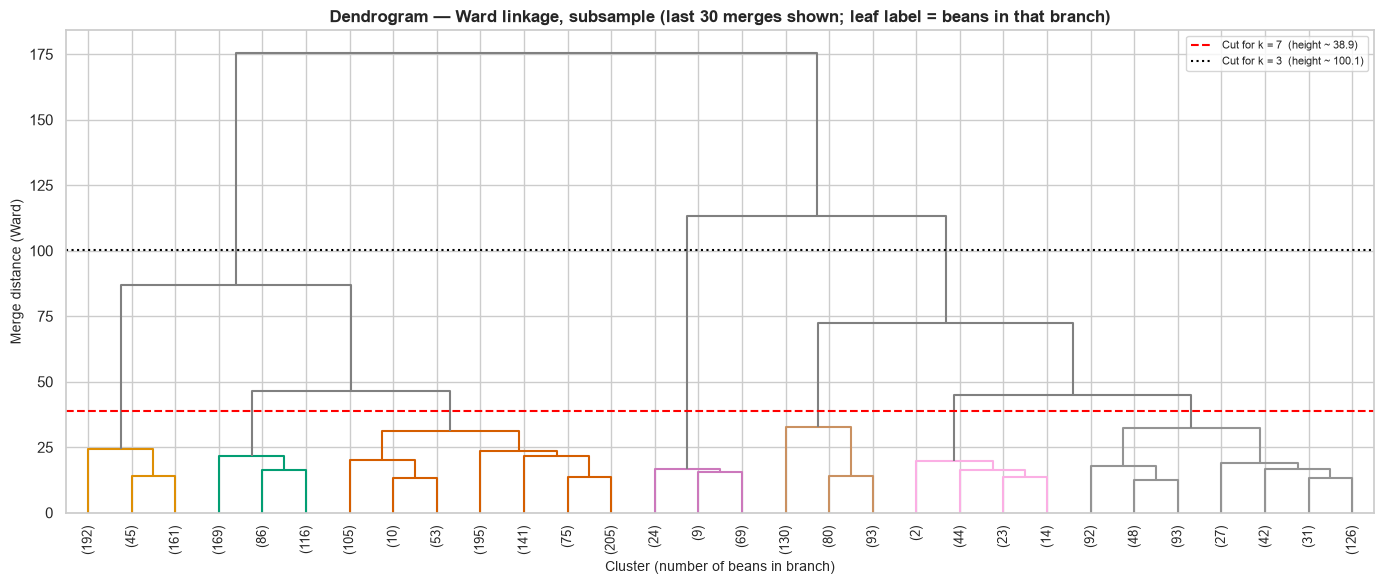

k after cut,2,3,4,5,6,7,8,9,10,11,12
merge height,175.30,113.44,86.79,72.54,46.46,45.09,32.62,32.24,31.13,24.37,23.53
jump to next merge,61.86,26.66,14.25,26.08,1.37,12.47,0.38,1.11,6.76,0.84,NaN


Largest jump in merge height occurs when going from k = 2 to k = 3 clusters


In [18]:
L_ward = linkage(REF_SUB, method="ward")
def cut_height(L, k):                       # height that yields exactly k clusters
    return (L[-k, 2] + L[-(k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(14, 6))
thr7 = cut_height(L_ward, 7)
dendrogram(L_ward, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90., leaf_font_size=9,
           color_threshold=thr7, above_threshold_color="gray", ax=ax)
ax.axhline(thr7, ls="--", color="red", label=f"Cut for k = 7  (height ~ {thr7:.1f})")
ax.axhline(cut_height(L_ward, 3), ls=":", color="black", label=f"Cut for k = 3  (height ~ {cut_height(L_ward, 3):.1f})")
ax.set_title("Dendrogram — Ward linkage, subsample (last 30 merges shown; leaf label = beans in that branch)")
ax.set_xlabel("Cluster (number of beans in branch)"); ax.set_ylabel("Merge distance (Ward)"); ax.legend()
plt.tight_layout(); plt.show()

# merge-height gaps: a big jump suggests a natural place to cut the tree
gaps = pd.DataFrame({"k after cut": np.arange(2, 13), "merge height": L_ward[-11:, 2][::-1]}).set_index("k after cut")
gaps["jump to next merge"] = gaps["merge height"] - gaps["merge height"].shift(-1)
display(gaps.round(2).T)
print("Largest jump in merge height occurs when going from k =", int(gaps["jump to next merge"].idxmax()), "to k =", int(gaps["jump to next merge"].idxmax()) + 1, "clusters")

**Observation.** The dendrogram shows a small number of very tall merges at the top of the tree (the coarse structure, with the large-bodied Bombay beans splitting off early) followed by a sequence of progressively smaller merges among the remaining varieties — visually confirming what the EDA already suggested: one variety is an easy, well-separated cluster, and the rest form a nested hierarchy of increasingly subtle sub-groups. The "jump to next merge" table pinpoints where the largest relative gaps in merge height occur, which is a second, complementary way (besides the elbow curve) to justify a choice of `k`.

### 7.2 Comparing linkage strategies (dendrograms + metrics at k = 7)

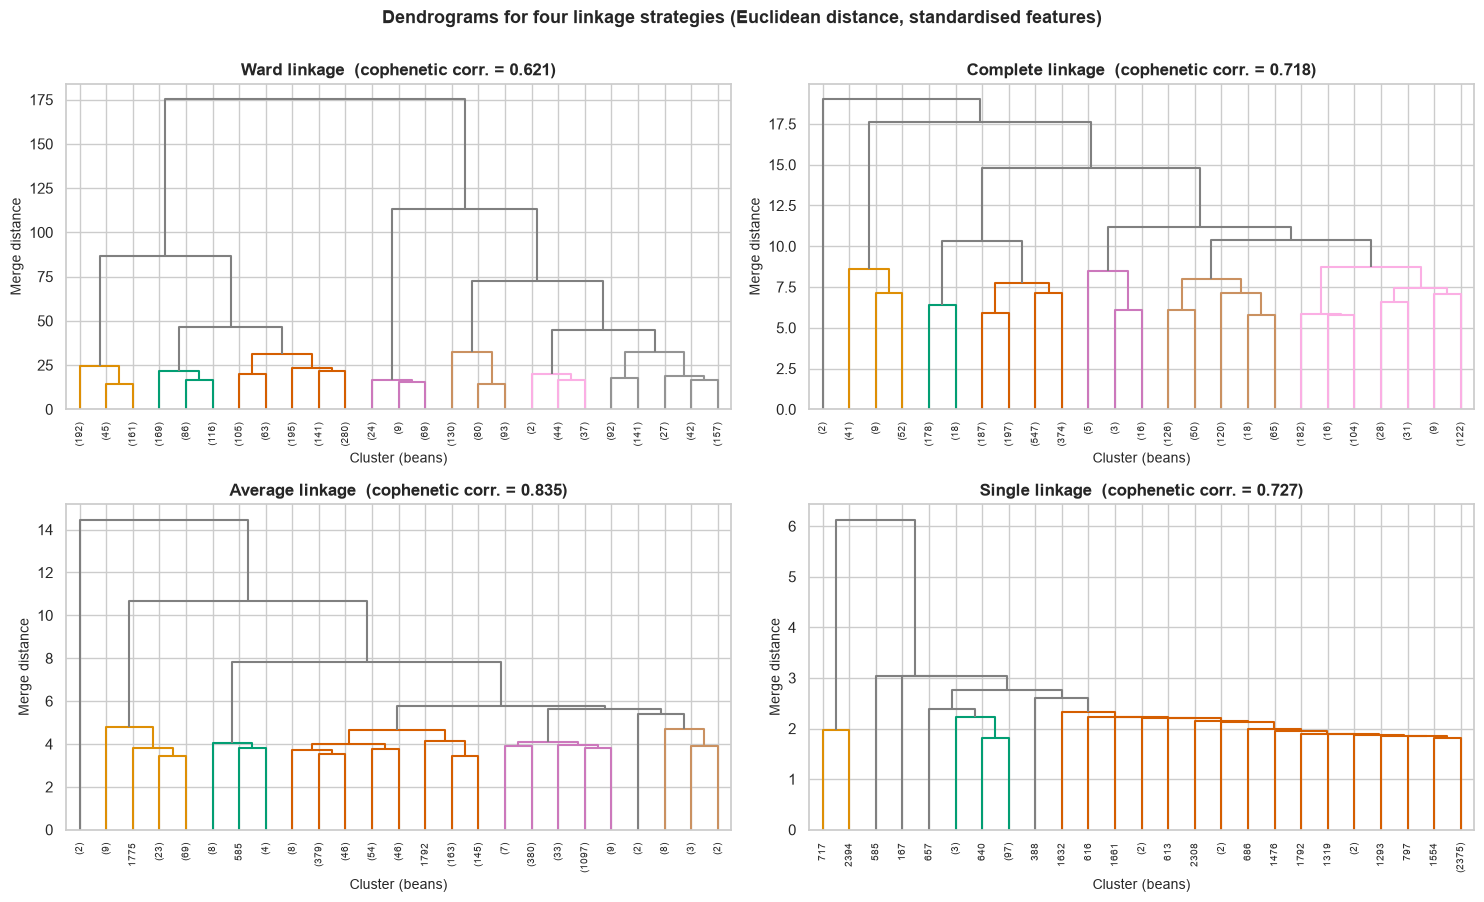

,cophenetic,silhouette,davies_bouldin,calinski_harabasz,ARI (post-hoc),smallest cluster (beans),largest cluster (beans)
linkage,,,,,,,
ward,0.6210,0.2942,1.1282,1369.4773,0.5731,83,784
complete,0.7183,0.2963,0.9217,956.8857,0.4128,2,1305
average,0.8349,0.3480,0.9079,585.9382,0.3120,2,1526
single,0.7267,0.3264,0.4490,148.6728,0.0349,1,2393


In [19]:
LINKS = ["ward", "complete", "average", "single"]
D_euc = pdist(REF_SUB, "euclidean")
Ls, coph = {}, {}
for m in LINKS:
    Ls[m] = linkage(D_euc, method=m); coph[m] = cophenet(Ls[m], D_euc)[0]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.ravel(), LINKS):
    dendrogram(Ls[m], truncate_mode="lastp", p=25, no_labels=False, show_leaf_counts=True, leaf_rotation=90., leaf_font_size=7,
               color_threshold=cut_height(Ls[m], 7), above_threshold_color="gray", ax=ax)
    ax.set_title(f"{m.capitalize()} linkage  (cophenetic corr. = {coph[m]:.3f})"); ax.set_xlabel("Cluster (beans)"); ax.set_ylabel("Merge distance")
plt.suptitle("Dendrograms for four linkage strategies (Euclidean distance, standardised features)", fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

rows = []
for m in LINKS:
    lab = fcluster(Ls[m], 7, "maxclust") - 1
    rows.append({"linkage": m, "cophenetic": coph[m], **internal_metrics(REF_SUB, lab), "ARI (post-hoc)": adjusted_rand_score(y_sub, lab),
                 "smallest cluster (beans)": np.bincount(lab).min(), "largest cluster (beans)": np.bincount(lab).max()})
link_df = pd.DataFrame(rows).set_index("linkage"); display(link_df.round(4))

**Observation.** `single` linkage shows classic "chaining" — long stringy merges that peel off one or two points at a time, producing one giant cluster plus several near-singleton clusters (visible in the very small "smallest cluster" size and the very lopsided "largest cluster" size in the table). `ward` gives the most balanced, compact clusters, which is why it is also scikit-learn's default and why it is used for the mandatory dendrogram above. `complete` and `average` usually sit in between. This comparison table is exactly the trade-off that motivates the linkage search inside the Section 8.2 tuning grid, rather than accepting the default blindly.

### 7.3 Baseline Agglomerative model on the full dataset
Scikit-learn default configuration (`ward` linkage, Euclidean distance) with `k = 7`, fitted on **all** standardised beans.

In [20]:
t0 = time.time()
agg_base = AgglomerativeClustering(n_clusters=7).fit(REF)
lab_agg_base = agg_base.labels_
print(f"Baseline Agglomerative fitted in {time.time()-t0:.1f}s | cluster sizes: {np.bincount(lab_agg_base)}")
display(pd.Series(full_report(REF, lab_agg_base), name="Agglomerative baseline (ward, k=7)").round(4).to_frame().T)

Baseline Agglomerative fitted in 4.2s | cluster sizes: [2755 1603 3867 1944 2507  522  345]


,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,homogeneity,completeness,v_measure,purity,n_clusters,min_share
"Agglomerative baseline (ward, k=7)",0.2886,1.1266,7237.0082,0.6749,0.7306,0.7128,0.7493,0.7306,0.798,7.0,0.0255
